# Review of model and strategy results

This notebook brings together saved results from the five-fold model comparison, the long-or-cash backtest, the indicator ablation, and the fold robustness review. It reads existing CSV files; it does not fit models or tune settings.

The tables are evidence for review, not dissertation conclusions. The test folds have already been inspected, and transaction-cost values are illustrative per-side scenarios.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Keep all inputs and the derived comparison table inside the project.
ROOT = Path.cwd()
RESULTS = ROOT / 'results'
fold_metrics = pd.read_csv(RESULTS / 'advanced_model_fold_metrics.csv')
backtest = pd.read_csv(RESULTS / 'long_or_cash_backtest_summary.csv')
indicator_deltas = pd.read_csv(RESULTS / 'indicator_ablation_deltas.csv')
robustness = pd.read_csv(RESULTS / 'robustness_backtest_stability.csv')
print(f"Loaded {len(fold_metrics)} fold-metric rows and {len(backtest)} cost-scenario backtests.")

Loaded 50 fold-metric rows and 50 cost-scenario backtests.


## Check that the saved tables line up

Before comparing results, check that each ETF has five folds, model rows are unique within each fold, and the backtest includes all five cost scenarios.

In [2]:
# A duplicate here would count the same model/fold more than once in the averages.
assert not fold_metrics.duplicated(['ETF', 'fold', 'model']).any()
assert not backtest.duplicated(['ETF', 'model', 'cost_bps_per_side']).any()
assert set(fold_metrics['ETF']) == {'QQQ', 'SPY'}
assert fold_metrics.groupby('ETF')['fold'].nunique().eq(5).all()
assert sorted(backtest['cost_bps_per_side'].unique()) == [0.0, 1.0, 2.5, 5.0, 10.0]
print('Coverage and uniqueness checks passed.')

Coverage and uniqueness checks passed.


## Predictive performance across folds

The means summarize five chronological test periods. Standard deviation and range show how much accuracy varied between them. ROC-AUC is missing for the two hard-label baselines because they do not provide probability scores.

In [3]:
# Keep fold variation visible rather than reporting only one average score.
predictive_summary = (
    fold_metrics.groupby(['ETF', 'model'], sort=True)
    .agg(
        folds=('fold', 'nunique'),
        mean_accuracy=('accuracy', 'mean'),
        sd_accuracy=('accuracy', 'std'),
        min_accuracy=('accuracy', 'min'),
        max_accuracy=('accuracy', 'max'),
        mean_balanced_accuracy=('balanced_accuracy', 'mean'),
        mean_f1_up=('f1_up', 'mean'),
        mean_roc_auc=('roc_auc', 'mean'),
    )
    .reset_index()
)
predictive_summary.sort_values(['ETF', 'mean_accuracy'], ascending=[True, False])

,ETF,model,folds,mean_accuracy,sd_accuracy,min_accuracy,max_accuracy,mean_balanced_accuracy,mean_f1_up,mean_roc_auc
4,QQQ,XGBoost,5,0.515317,0.010405,0.503675,0.529050,0.513830,0.574276,0.523043
1,QQQ,LSTM,5,0.514181,0.006903,0.507751,0.525869,0.511830,0.599876,0.519153
2,QQQ,Logistic regression,5,0.507456,0.007320,0.497406,0.518024,0.504211,0.622048,0.513531
3,QQQ,Majority baseline,5,0.505541,0.003400,0.500424,0.508647,0.500000,0.671568,NaN
0,QQQ,Direction persistence baseline,5,0.481307,0.014117,0.456743,0.493098,0.481297,0.484014,NaN
9,SPY,XGBoost,5,0.517481,0.011359,0.498436,0.526459,0.516287,0.578313,0.528344
6,SPY,LSTM,5,0.513167,0.013302,0.495725,0.530029,0.512051,0.599367,0.525837
7,SPY,Logistic regression,5,0.513009,0.008676,0.503650,0.522673,0.511335,0.588438,0.519527
8,SPY,Majority baseline,5,0.504164,0.008595,0.494960,0.516381,0.500000,0.670323,NaN
5,SPY,Direction persistence baseline,5,0.478864,0.009820,0.463881,0.489895,0.478834,0.480239,NaN


## Paired comparison with the majority baseline

For each fold, compare each model's accuracy with the majority baseline from the same ETF and test period. Counting positive-fold differences is descriptive; five folds are too few to make this a significance test.

In [4]:
# Pair on ETF and fold so each model is compared with the matching test period.
majority = fold_metrics.loc[
    fold_metrics['model'].eq('Majority baseline'),
    ['ETF', 'fold', 'accuracy', 'balanced_accuracy'],
].rename(columns={
    'accuracy': 'majority_accuracy',
    'balanced_accuracy': 'majority_balanced_accuracy',
})
paired = fold_metrics.merge(
    majority,
    on=['ETF', 'fold'],
    how='left',
    validate='many_to_one',
)
paired['accuracy_delta_vs_majority'] = paired['accuracy'] - paired['majority_accuracy']
paired['balanced_accuracy_delta_vs_majority'] = (
    paired['balanced_accuracy'] - paired['majority_balanced_accuracy']
)
paired_summary = (
    paired.groupby(['ETF', 'model'], sort=True)
    .agg(
        folds=('fold', 'nunique'),
        mean_accuracy_delta=('accuracy_delta_vs_majority', 'mean'),
        folds_above_majority=('accuracy_delta_vs_majority', lambda x: int((x > 0).sum())),
        mean_balanced_accuracy_delta=('balanced_accuracy_delta_vs_majority', 'mean'),
    )
    .reset_index()
)
paired_summary.sort_values(['ETF', 'model'])

,ETF,model,folds,mean_accuracy_delta,folds_above_majority,mean_balanced_accuracy_delta
0,QQQ,Direction persistence baseline,5,-0.024233,0,-0.018703
1,QQQ,LSTM,5,0.008640,5,0.011830
2,QQQ,Logistic regression,5,0.001915,2,0.004211
3,QQQ,Majority baseline,5,0.000000,0,0.000000
4,QQQ,XGBoost,5,0.009776,4,0.013830
5,SPY,Direction persistence baseline,5,-0.025300,0,-0.021166
6,SPY,LSTM,5,0.009003,4,0.012051
7,SPY,Logistic regression,5,0.008845,4,0.011335
8,SPY,Majority baseline,5,0.000000,0,0.000000
9,SPY,XGBoost,5,0.013317,4,0.016287


## Trading performance under the cost scenarios

These are continuous-period backtest summaries over the shared out-of-sample predictions. Costs are applied per side. Returns are hypothetical and depend on the next-bar-open execution assumption.

In [5]:
# Show all tested cost assumptions so the sensitivity is easy to compare.
strategy_columns = [
    'ETF', 'model', 'cost_bps_per_side', 'net_cumulative_return',
    'maximum_drawdown', 'annualized_daily_sharpe', 'entries_per_session',
    'exposure_fraction', 'one_way_turnover',
]
strategy_summary = backtest[strategy_columns].sort_values(
    ['ETF', 'model', 'cost_bps_per_side']
)
strategy_summary

,ETF,model,cost_bps_per_side,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe,entries_per_session,exposure_fraction,one_way_turnover
5,QQQ,Direction persistence baseline,0.0,-0.213640,-0.214474,-1.614905,13.230603,0.499808,12278.0
6,QQQ,Direction persistence baseline,1.0,-0.769661,-0.769661,-9.728473,13.230603,0.499808,12278.0
7,QQQ,Direction persistence baseline,2.5,-0.963492,-0.963492,-20.564345,13.230603,0.499808,12278.0
8,QQQ,Direction persistence baseline,5.0,-0.998306,-0.998306,-34.653787,13.230603,0.499808,12278.0
9,QQQ,Direction persistence baseline,10.0,-0.999996,-0.999996,-51.248591,13.230603,0.499808,12278.0
20,QQQ,LSTM,0.0,0.165072,-0.065568,1.082548,8.127155,0.709595,7542.0
21,QQQ,LSTM,1.0,-0.451986,-0.452526,-4.123478,8.127155,0.709595,7542.0
22,QQQ,LSTM,2.5,-0.823238,-0.823238,-11.922132,8.127155,0.709595,7542.0
23,QQQ,LSTM,5.0,-0.973195,-0.973195,-23.404675,8.127155,0.709595,7542.0
24,QQQ,LSTM,10.0,-0.999384,-0.999384,-37.245058,8.127155,0.709595,7542.0


## Join predictive and trading summaries

The joined table places mean fold accuracy beside the continuous-period strategy outcomes. The 0 bp column is a gross reference; 1 bp per side is an illustrative cost case, not a verified execution estimate.

In [6]:
# Normalize model labels only for joining; keep the original labels for display.
predictive_for_join = predictive_summary.copy()
strategy_for_join = backtest.loc[
    backtest['cost_bps_per_side'].isin([0.0, 1.0])
].copy()
predictive_for_join['model_key'] = predictive_for_join['model'].str.strip().str.lower()
strategy_for_join['model_key'] = strategy_for_join['model'].str.strip().str.lower()

comparison = predictive_for_join.merge(
    strategy_for_join,
    on=['ETF', 'model_key'],
    how='inner',
    validate='one_to_many',
    suffixes=('_predictive', '_strategy'),
)
comparison_table = comparison[[
    'ETF', 'model_predictive', 'folds', 'mean_accuracy', 'sd_accuracy',
    'mean_balanced_accuracy', 'mean_f1_up', 'mean_roc_auc',
    'cost_bps_per_side', 'net_cumulative_return', 'maximum_drawdown',
    'annualized_daily_sharpe', 'entries_per_session', 'exposure_fraction',
]].sort_values(['ETF', 'model_predictive', 'cost_bps_per_side'])

# Save a compact table that can be reviewed without rerunning this notebook.
comparison_table.to_csv(RESULTS / 'model_strategy_comparison.csv', index=False)
comparison_table

,ETF,model_predictive,folds,mean_accuracy,sd_accuracy,mean_balanced_accuracy,mean_f1_up,mean_roc_auc,cost_bps_per_side,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe,entries_per_session,exposure_fraction
0,QQQ,Direction persistence baseline,5,0.481307,0.014117,0.481297,0.484014,NaN,0.0,-0.213640,-0.214474,-1.614905,13.230603,0.499808
1,QQQ,Direction persistence baseline,5,0.481307,0.014117,0.481297,0.484014,NaN,1.0,-0.769661,-0.769661,-9.728473,13.230603,0.499808
2,QQQ,LSTM,5,0.514181,0.006903,0.511830,0.599876,0.519153,0.0,0.165072,-0.065568,1.082548,8.127155,0.709595
3,QQQ,LSTM,5,0.514181,0.006903,0.511830,0.599876,0.519153,1.0,-0.451986,-0.452526,-4.123478,8.127155,0.709595
4,QQQ,Logistic regression,5,0.507456,0.007320,0.504211,0.622048,0.513531,0.0,0.073871,-0.077835,0.498398,6.922414,0.799650
5,QQQ,Logistic regression,5,0.507456,0.007320,0.504211,0.622048,0.513531,1.0,-0.435132,-0.436168,-3.703547,6.922414,0.799650
6,QQQ,Majority baseline,5,0.505541,0.003400,0.500000,0.671568,NaN,0.0,0.059644,-0.096909,0.313251,1.068966,1.000000
7,QQQ,Majority baseline,5,0.505541,0.003400,0.500000,0.671568,NaN,1.0,-0.040432,-0.111244,-0.117906,1.068966,1.000000
8,QQQ,XGBoost,5,0.515317,0.010405,0.513830,0.574276,0.523043,0.0,0.371844,-0.062964,2.250617,11.327586,0.634058
9,QQQ,XGBoost,5,0.515317,0.010405,0.513830,0.574276,0.523043,1.0,-0.520541,-0.520541,-5.143173,11.327586,0.634058


## Indicator ablation: matched-sample changes

The indicator deltas compare base features with base-plus-indicator features on the same smaller, warm-up-complete sample. Do not compare these absolute scores directly with the full-sample model summary above.

In [7]:
# Focus the view on XGBoost while retaining both ETFs and every reported metric.
xgboost_indicator_delta = indicator_deltas.loc[
    indicator_deltas['model'].str.strip().str.lower().eq('xgboost')
].sort_values('ETF')
xgboost_indicator_delta

,ETF,comparison,model,accuracy_indicators,balanced_accuracy_indicators,f1_up_indicators,roc_auc_indicators,accuracy_base,balanced_accuracy_base,f1_up_base,roc_auc_base,accuracy_delta,balanced_accuracy_delta,f1_up_delta,roc_auc_delta
4,QQQ,+ technical indicators minus base,XGBoost,0.512976,0.512039,0.572095,0.518282,0.515427,0.514515,0.574419,0.524460,-0.002451,-0.002476,-0.002324,-0.006177
9,SPY,+ technical indicators minus base,XGBoost,0.514420,0.514845,0.568588,0.526635,0.514657,0.514957,0.571833,0.528657,-0.000237,-0.000113,-0.003245,-0.002022


## Fold-to-fold strategy variation

The robustness returns treat each fold as a separate portfolio that starts and ends flat. They are not compounded together and are not the same calculation as the continuous-period backtest above.

In [8]:
# Use XGBoost as an example and show how many folds were positive at each cost.
xgboost_robustness = robustness.loc[
    robustness['model'].eq('XGBoost'),
    ['ETF', 'cost_bps_per_side', 'folds', 'positive_return_folds',
     'mean_net_cumulative_return', 'minimum_net_cumulative_return',
     'maximum_net_cumulative_return', 'mean_maximum_drawdown'],
].sort_values(['ETF', 'cost_bps_per_side'])
xgboost_robustness

,ETF,cost_bps_per_side,folds,positive_return_folds,mean_net_cumulative_return,minimum_net_cumulative_return,maximum_net_cumulative_return,mean_maximum_drawdown
20,QQQ,0.0,5,5,0.065290,0.057410,0.075726,-0.032046
21,QQQ,1.0,5,0,-0.136680,-0.145962,-0.120511,-0.146879
22,QQQ,2.5,5,0,-0.370131,-0.386784,-0.349860,-0.371386
23,QQQ,5.0,5,0,-0.627518,-0.646985,-0.607122,-0.627518
24,QQQ,10.0,5,0,-0.869674,-0.883058,-0.856585,-0.869674
45,SPY,0.0,5,5,0.050645,0.005763,0.090743,-0.032222
46,SPY,1.0,5,0,-0.152494,-0.187624,-0.121153,-0.158312
47,SPY,2.5,5,0,-0.385903,-0.422098,-0.353640,-0.385903
48,SPY,5.0,5,0,-0.640886,-0.672434,-0.612714,-0.640886
49,SPY,10.0,5,0,-0.877015,-0.894803,-0.861011,-0.877015


## Visual comparison: accuracy and 1 bp scenario return

The panels use separate scales: classification accuracy is a fold mean, while net return is the full-period strategy result. Read the return panel with the illustrative-cost and execution assumptions in mind.

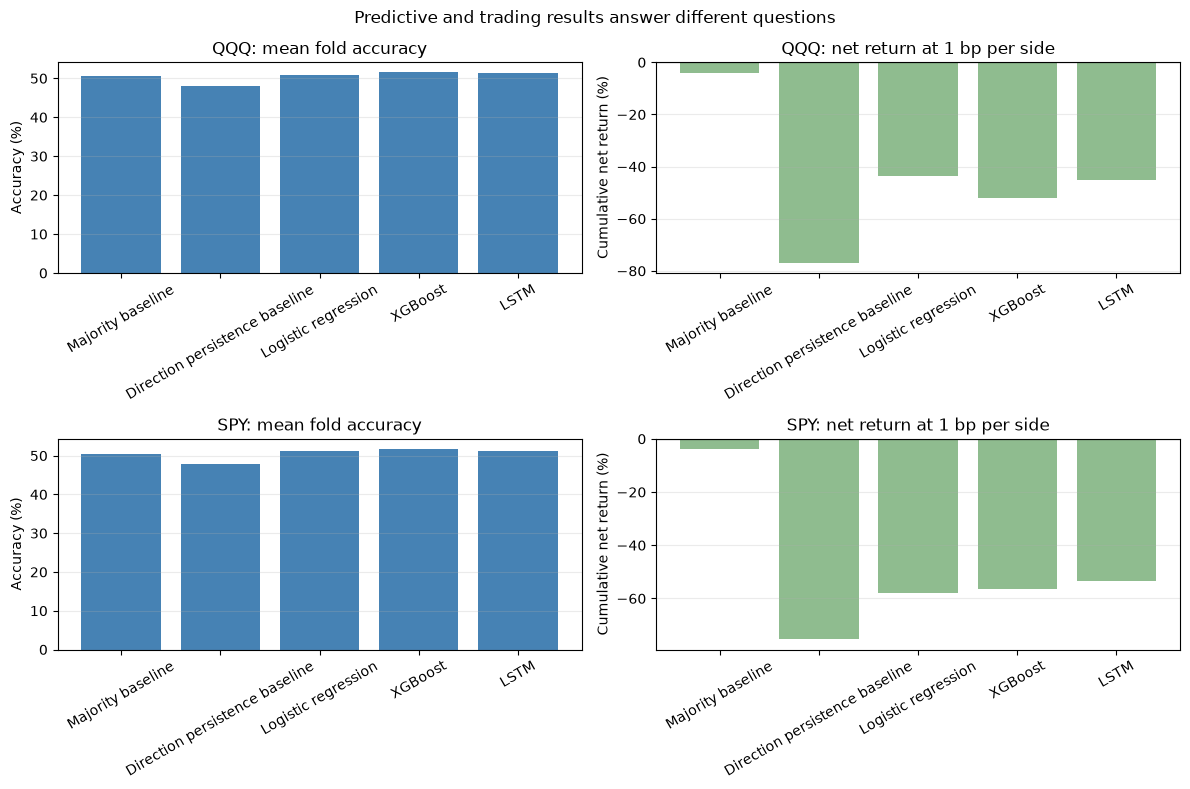

In [9]:
# Use side-by-side panels instead of one axis because the metrics have different units.
plot_rows = comparison.loc[comparison['cost_bps_per_side'].eq(1.0)]
models = [
    'Majority baseline', 'Direction persistence baseline',
    'Logistic regression', 'XGBoost', 'LSTM',
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, ticker in enumerate(['QQQ', 'SPY']):
    ticker_rows = plot_rows.loc[plot_rows['ETF'].eq(ticker)].set_index('model_predictive')
    ordered = ticker_rows.reindex(models)
    axes[row, 0].bar(models, ordered['mean_accuracy'] * 100, color='steelblue')
    axes[row, 0].set_title(f'{ticker}: mean fold accuracy')
    axes[row, 0].set_ylabel('Accuracy (%)')
    axes[row, 1].bar(models, ordered['net_cumulative_return'] * 100, color='darkseagreen')
    axes[row, 1].axhline(0, color='black', linewidth=0.8)
    axes[row, 1].set_title(f'{ticker}: net return at 1 bp per side')
    axes[row, 1].set_ylabel('Cumulative net return (%)')
    for axis in axes[row]:
        axis.tick_params(axis='x', rotation=30)
        axis.grid(axis='y', alpha=0.25)
fig.suptitle('Predictive and trading results answer different questions')
fig.tight_layout()
plt.show()

## Questions to answer before choosing the final scope

- Which models improve on the majority and direction-persistence baselines across more than one fold?
- Does a small accuracy difference translate into a better cost-adjusted strategy result?
- How much do drawdown and turnover change the business interpretation?
- What can and cannot be concluded when the cost values are illustrative and the IEX data do not contain consolidated market-wide volume?
- Which findings should you verify and explain in your own words for the report?